# Phase 3 Research — Learned Hypergraph Equivalence

This clean-executed notebook reads final artifacts rather than recomputing or
silently altering them. It separates the designated learned primary from
fixed-cost algorithmic controls and the exact oracle.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "phase3_spec.json").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "results" / "phase3"

def read_json(relative):
    return json.loads((RESULTS / relative).read_text(encoding="utf-8"))

spec = json.loads((ROOT / "phase3_spec.json").read_text(encoding="utf-8"))
aggregate = pd.read_csv(RESULTS / "aggregate_metrics.csv")
per_seed = pd.read_csv(RESULTS / "per_seed_metrics.csv")
zero_shot = pd.read_csv(RESULTS / "zero_shot_metrics.csv")
label_signal = pd.read_csv(
    RESULTS / "controls" / "supervised_only_label_signal_control_metrics.csv"
)
pretraining_confound = pd.read_csv(
    RESULTS / "controls" / "full_pipeline_pretraining_confound_metrics.csv"
)
split_audit = read_json("split_overlap_audit.json")
benchmark_audit = read_json("learned_benchmark_audit.json")
benchmark_lock = read_json("learned_benchmark_lock.json")
gate_a = read_json("gate_a_report.json")
gate_b = read_json("gate_b_report.json")
gate_c = read_json("gate_c_report.json")
numerical = read_json("numerical_audit.json")
scientific = read_json("scientific_claim_audit.json")
selection = read_json("model_selection/model_selection_protocol.json")

assert spec["primary_model"] == "LearnedSinkhornMatcher"
print("Loaded final benchmark:", spec["benchmark_version"])
print("Designated primary:", spec["primary_model"])

Loaded final benchmark: learned_benchmark_v2_final
Designated primary: LearnedSinkhornMatcher


## Scope, split definitions, and benchmark difficulty

Class 0 is EE-equivalent but not strongly structurally equivalent; class 1 has
the same multiset of incident neighbor sets. Each matched pair shares nuisance
statistics. Train and validation are byte-identical to preserved development
v1; final-v2 IID, OOD-template, and OOD-size samples use new, unseen offsets.
The selected v5 recipe was frozen before these final-v2 tests were evaluated.
This is a post-selection final-test lock—not a claim that v2 existed before
development optimization.

In [2]:
rows = []
for split, report in benchmark_audit["split_reports"].items():
    rows.append({
        "split": split,
        "samples": report["sample_count"],
        "class 0": report["class_counts"]["0"],
        "class 1": report["class_counts"]["1"],
        "negative cost min": report["negative_hungarian_cost"]["minimum"],
        "negative cost max": report["negative_hungarian_cost"]["maximum"],
        "hard negatives (cost 4)": report[
            "negative_hungarian_cost"
        ]["hard_negative_count_cost_4"],
        "max nuisance AUC": report["nuisance_scalar_max_auc"],
    })
display(pd.DataFrame(rows))
assert split_audit["status"] == "PASS"
assert benchmark_audit["status"] == "PASS"
assert split_audit["problem_count"] == 0
assert benchmark_lock["locked_before_first_final_test_evaluation"] is True
assert benchmark_lock["locked_before_first_optimization"] is False

,split,samples,class 0,class 1,negative cost min,negative cost max,hard negatives (cost 4),max nuisance AUC
0,iid_test,800,400,400,4.0,14.0,271,0.5
1,ood_size_test,400,200,200,4.0,16.0,57,0.5
2,ood_template_test,800,400,400,4.0,20.0,158,0.5
3,train,800,400,400,4.0,16.0,281,0.5
4,validation,800,400,400,4.0,16.0,276,0.5


## Model identity and methodology

`LearnedSinkhornMatcher` is the designated primary. It starts from random
weights, encodes column pairs symmetrically, learns row-pair scores/costs,
computes normalized-mass Sinkhorn transport, and learns the final classifier.
It receives only the two incidence matrices. It does not receive fixed L1
cost, Hungarian output, labels, IDs, hashes, or split names.

`MLP_Baseline`, `NestedDeepSets`, and `BipartiteEncoder` are learned baselines;
`LearnedNoSinkhorn` and `LearnedNoColumnContext` are ablations.
`DeterministicDifferentiableMatching`, `FixedL1ResidualSinkhorn`,
`FixedL1StraightThroughHungarian`, and `ExactHungarianOracle` are reported
separately as algorithmic/hybrid/oracle evidence.

## Zero-shot versus trained evidence

Chance-level zero-shot primary behavior, five distinct initial/final states,
five seed-dependent training orders, and a material post-training improvement
are mandatory checks. Candidate v1 exposed development-test metrics; those v1
tests were retired from final claims. Candidate v5 was selected using only
train/validation evidence, then evaluated on unseen final-v2 tests.

In [3]:
primary = spec["primary_model"]
primary_zero = zero_shot[
    (zero_shot["model"] == primary)
    & zero_shot["split"].isin(["train", "validation"])
]
primary_trained = per_seed[
    (per_seed["model"] == primary)
    & per_seed["split"].isin(["train", "validation"])
]
learning = (
    primary_zero.groupby("split")[["accuracy", "macro_f1", "roc_auc"]].mean()
    .add_prefix("zero_shot_")
    .join(
        primary_trained.groupby("split")[
            ["accuracy", "macro_f1", "roc_auc"]
        ].mean().add_prefix("trained_")
    )
)
display(learning)
assert len(primary_trained["seed"].unique()) == 5
assert scientific["checks"]["five_independent_primary_seeds"]["status"] == "PASS"
assert scientific["checks"]["training_improves_primary"]["status"] == "PASS"

,zero_shot_accuracy,zero_shot_macro_f1,zero_shot_roc_auc,trained_accuracy,trained_macro_f1,trained_roc_auc
split,,,,,,
train,0.5,0.333333,0.551987,1.0,1.0,1.0
validation,0.5,0.333333,0.552481,1.0,1.0,1.0


## Five-seed IID and OOD results

Means and sample standard deviations use locked seeds 42, 100, 2026, 777, and
999. Validation alone selects checkpoints; all test splits are evaluation-only.

In [4]:
test_splits = ["iid_test", "ood_template_test", "ood_size_test"]
columns = [
    "model", "role", "split", "loss_mean", "accuracy_mean", "accuracy_std",
    "balanced_accuracy_mean", "macro_f1_mean", "macro_f1_std",
    "roc_auc_mean", "roc_auc_std", "seed_count",
]
test_metrics = aggregate[aggregate["split"].isin(test_splits)][columns]
role_order = {
    "primary_learned": 0, "baseline": 1, "ablation": 2,
    "algorithmic_hybrid": 3, "algorithmic_baseline": 4, "oracle": 5,
}
test_metrics = test_metrics.assign(
    role_order=test_metrics["role"].map(role_order)
).sort_values(["role_order", "model", "split"]).drop(columns="role_order")
display(test_metrics)
assert len(test_metrics) == 10 * 3
assert (test_metrics["seed_count"] == 5).all()

,model,role,split,loss_mean,accuracy_mean,accuracy_std,balanced_accuracy_mean,macro_f1_mean,macro_f1_std,roc_auc_mean,roc_auc_std,seed_count
2,LearnedSinkhornMatcher,primary_learned,iid_test,8.076874e-06,1.00000,0.000000,1.00000,1.000000,0.000000,1.000000,0.000000e+00,5
4,LearnedSinkhornMatcher,primary_learned,ood_size_test,4.025965e-03,1.00000,0.000000,1.00000,1.000000,0.000000,1.000000,0.000000e+00,5
3,LearnedSinkhornMatcher,primary_learned,ood_template_test,8.280782e-06,1.00000,0.000000,1.00000,1.000000,0.000000,1.000000,0.000000e+00,5
17,BipartiteEncoder,baseline,iid_test,6.931503e-01,0.50000,0.000000,0.50000,0.491278,0.011727,0.500003,4.941059e-06,5
19,BipartiteEncoder,baseline,ood_size_test,6.931488e-01,0.50000,0.000000,0.50000,0.442169,0.047293,0.499995,2.592055e-05,5
18,BipartiteEncoder,baseline,ood_template_test,6.931500e-01,0.50000,0.000000,0.50000,0.488569,0.015260,0.499998,7.194290e-06,5
7,MLP_Baseline,baseline,iid_test,6.935439e-01,0.50000,0.000000,0.50000,0.494946,0.005656,0.500000,3.925231e-17,5
9,MLP_Baseline,baseline,ood_size_test,6.933766e-01,0.50000,0.000000,0.50000,0.394586,0.041705,0.500000,0.000000e+00,5
8,MLP_Baseline,baseline,ood_template_test,6.935174e-01,0.50000,0.000000,0.50000,0.492580,0.007803,0.500000,6.206335e-17,5
12,NestedDeepSets,baseline,iid_test,6.931477e-01,0.50000,0.000000,0.50000,0.486710,0.010991,0.499976,3.252103e-05,5


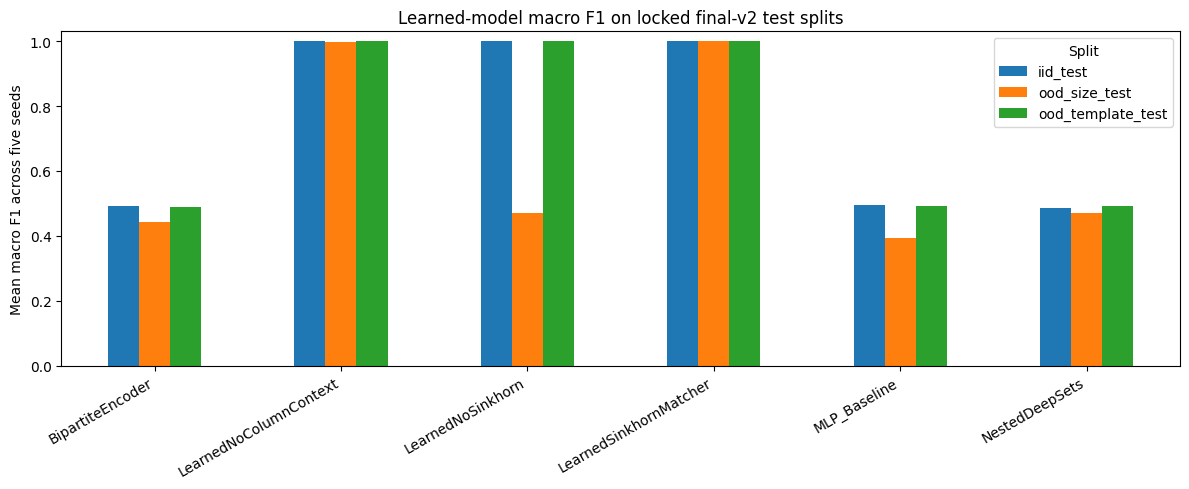

In [5]:
learned_roles = ["primary_learned", "baseline", "ablation"]
plot_data = test_metrics[
    test_metrics["role"].isin(learned_roles)
].pivot(index="model", columns="split", values="macro_f1_mean")
ax = plot_data.plot(kind="bar", figsize=(12, 5), ylim=(0, 1.03))
ax.set_title("Learned-model macro F1 on locked final-v2 test splits")
ax.set_ylabel("Mean macro F1 across five seeds")
ax.set_xlabel("")
ax.legend(title="Split")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Negative and positive controls

The supervised-label-signal shuffled/random controls disable only label-free
structural pretraining, then test whether corrupted class labels can create
held-out success. The original full-pipeline invalid-label run is also shown:
it is a preserved failed/confounded control because self-supervised structural
pretraining supplies task signal without class labels. The label-access
positive control must score perfectly, while source inspection must show that
the real primary cannot access labels or metadata. Exact Hungarian establishes
that the task is algorithmically separable without being misreported as
learned discovery.

In [6]:
control_summary = (
    label_signal[
        label_signal["split"].isin(
            ["iid_test", "ood_template_test", "ood_size_test"]
        )
    ]
    .groupby(["control", "split"])
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        seeds=("seed", "nunique"),
    )
    .reset_index()
)
display(control_summary)
display(
    pretraining_confound[
        pretraining_confound["split"].isin(
            ["iid_test", "ood_template_test", "ood_size_test"]
        )
    ]
    .groupby(["control", "split"])
    .agg(accuracy_mean=("accuracy", "mean"))
    .reset_index()
)
display(pd.DataFrame([
    {
        "check": name,
        "status": evidence["status"],
    }
    for name, evidence in scientific["checks"].items()
]))
assert scientific["status"] == "PASS"
assert (control_summary["seeds"] == 5).all()

,control,split,accuracy_mean,accuracy_std,macro_f1_mean,seeds
0,random,iid_test,0.48975,0.090357,0.486514,5
1,random,ood_size_test,0.50000,0.000000,0.333333,5
2,random,ood_template_test,0.49425,0.116641,0.490928,5
3,shuffled,iid_test,0.49425,0.020128,0.489143,5
4,shuffled,ood_size_test,0.50000,0.000000,0.333333,5
5,shuffled,ood_template_test,0.50325,0.031962,0.494272,5


,control,split,accuracy_mean
0,random,iid_test,0.6650
1,random,ood_size_test,0.5220
2,random,ood_template_test,0.6915
3,shuffled,iid_test,0.3690
4,shuffled,ood_size_test,0.5245
5,shuffled,ood_template_test,0.3675


,check,status
0,learned_primary_has_no_fixed_or_metadata_separ...,PASS
1,primary_zero_shot_is_chance_level,PASS
2,training_improves_primary,PASS
3,five_independent_primary_seeds,PASS
4,algorithmic_models_are_not_claimed_as_learned,PASS
5,oracle_separation_control,PASS
6,final_test_protocol_is_locked,PASS
7,label_access_positive_control,PASS
8,invalid_label_negative_controls,PASS
9,pretraining_confound_is_preserved_and_disclosed,PASS


## Gates and normalized Sinkhorn mass

Gate A verifies exact labels and convergence. A coupling is normalized to
total mass 1; with `m` equally weighted valid rows, a hard matched entry is
approximately `1/m`, not 1. Gate B retains the accuracy and macro-F1 threshold
of 0.99 and per-class F1 threshold of 0.98 for all seeds. Gate C uses
validation-only selection and checks the unchanged training thresholds.

In [7]:
gate_rows = [
    {
        "gate": "A",
        "status": gate_a["status"],
        "completed": gate_a.get("oracle_sample_count"),
        "key value": gate_a.get("oracle_accuracy"),
    },
    {
        "gate": "B",
        "status": gate_b["status"],
        "completed": gate_b["completed_seed_count"],
        "key value": min(row["accuracy"] for row in gate_b["per_seed"]),
    },
    {
        "gate": "C",
        "status": gate_c["status"],
        "completed": gate_c["completed_seed_count"],
        "key value": min(
            row["train_metrics"]["accuracy"] for row in gate_c["per_seed"]
        ),
    },
]
display(pd.DataFrame(gate_rows))
assert gate_a["status"] == gate_b["status"] == gate_c["status"] == "PASS"
assert gate_b["completed_seed_count"] == gate_c["completed_seed_count"] == 5

,gate,status,completed,key value
0,A,PASS,3600,1.0
1,B,PASS,5,1.0
2,C,PASS,5,1.0


## Complete float64 structural audit

Every primary checkpoint is tested on every final-v2 IID, OOD-template, and
OOD-size sample using compact unpadded float64 matrices and 500 Sinkhorn
iterations. Checks cover transpose equivariance, matching/equality/final-score
invariance, mass, marginals, finiteness, non-negativity, assignment transpose,
row permutations, and joint column permutations.

In [8]:
quantities = pd.DataFrame([
    {
        "quantity": name,
        "maximum": values["maximum"],
        "p95": values["p95"],
        "p99": values["p99"],
        "tolerance": values["tolerance"],
        "failures": values["failed_count"],
    }
    for name, values in numerical["quantities"].items()
])
display(quantities)
print("Audited seed-sample cases:", numerical["audited_sample_count"])
print("Failed cases:", numerical["failed_sample_count"])
assert numerical["status"] == "PASS"
assert numerical["failed_sample_count"] == 0
assert (quantities["failures"] == 0).all()

,quantity,maximum,p95,p99,tolerance,failures
0,cost_finite_violation,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-08,0
1,coupling_finite_violation,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-08,0
2,coupling_nonnegativity_violation,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-08,0
3,cost_transpose_error,1.136868e-13,0.000000e+00,4.440892e-16,1.000000e-08,0
4,coupling_transpose_error,1.468548e-13,4.204657e-14,6.931428e-14,1.000000e-08,0
5,assignment_transpose_error,1.468548e-13,4.204657e-14,6.931428e-14,1.000000e-08,0
6,matching_cost_swap_error,2.440270e-12,4.734435e-13,8.482548e-13,1.000000e-08,0
7,equality_score_swap_error,2.001177e-13,4.379049e-15,2.888301e-14,1.000000e-08,0
8,final_logit_swap_error,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-08,0
9,final_probability_swap_error,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-08,0


Audited seed-sample cases: 10000
Failed cases: 0


## Limitations and interpretation

The benchmark is synthetic and targets the local incidence-star definition;
it does not establish universal empirical-hypergraph performance. Five seeds
measure optimization variability on fixed data, not population uncertainty.
The final-v2 test remedy prevents the disclosed v1 incident from supporting
final claims, but the chronology remains a limitation that must be reported.
Exact fixed-cost success is useful algorithmic evidence, not learned evidence.
The preserved full-pipeline invalid-label FAIL demonstrates that the
self-supervised pretraining can learn structural task signal without class
labels; the separate supervised-only control supports only the narrower
claim about label corruption.

## Reproducibility commands

In [9]:
commands = [
    "python -m src.audit_learning_benchmark",
    "python -m src.audit_splits",
    "python -m src.run_final_experiments",
    "python -m src.run_gates",
    "python -m src.run_label_signal_controls",
    "python -m src.scientific_claim_audit",
    "python -m src.audit_model_numerics",
    "python -m src.reporting",
    "python -m pytest -q",
]
print("\n".join(commands))

python -m src.audit_learning_benchmark
python -m src.audit_splits
python -m src.run_final_experiments
python -m src.run_gates
python -m src.run_label_signal_controls
python -m src.scientific_claim_audit
python -m src.audit_model_numerics
python -m src.reporting
python -m pytest -q
